```markdown
# 02. Asynchronous Multimodal Portfolio Evaluator

Welcome to the second notebook of the **MultiModalAgents** series! In this project, we analyze a modeling portfolio containing **27 images**.

### Why Asynchronous Batching?
Instead of evaluating images sequentially (which would take a long time and is prone to network bottlenecks), we utilize Python's `asyncio` and a concurrency limit (`asyncio.Semaphore`) to process images in batches of **3**.

We utilize a structured multimodal vision model (`deepseek/deepseek-v4-flash-vision-exp`) to critique individual looks, and then feed those structured results into a high-tier reasoning model (`gpt-4o`) to compile a cohesive, professional creative critique.

---

## 1. Setup & API Initialization
First, we load the required APIs, set up the base environment variables, and initialize our LLM endpoints.
```

In [ ]:
import os
api_key = os.getenv("AICREDITS_API_KEY")
base_url = os.getenv("AICREDITS_BASE_URL")

from langchain_openai import ChatOpenAI

os.environ["OPENAI_API_KEY"] = api_key
os.environ["OPENAI_BASE_URL"] = base_url

llm = ChatOpenAI(model= "google/gemma-4-31b-it")
llm2= ChatOpenAI(model="deepseek/deepseek-v4-flash-vision-exp")

```markdown
## 2. Defining the Output Schema (Pydantic)
To ensure consistency in our evaluations, we define a structured output format using Pydantic. Each look is evaluated for its primary mood, styling details, and commercial campaign viability, which maps directly to the target schema expected from our vision model.
```

In [ ]:
from pydantic import BaseModel, Field

class LookBreakdown(BaseModel):
    look_number: int = Field(description="The index/number of the image in the sequence")
    primary_mood_or_genre: str = Field(description="e.g., High Fashion Editorial, Commercial, Athletic/Fitness")
    wardrobe_and_styling: str = Field(description="Brief assessment of the styling and outfit")
    ideal_campaign_fit: str = Field(description="Type of brand or campaign this look suits best (e.g., luxury streetwear, fitness apparel, tech wear)")

class PortfolioEvaluation(BaseModel):
    overall_versatility_score: int = Field(description="Score from 1 to 10 evaluating range across the submitted images")
    looks: list[LookBreakdown] = Field(description="Breakdown of each individual look provided")
    cohesion_and_critique: str = Field(description="An analysis of how well these images complement each other as a portfolio lineup and suggestions for improvement")

structured_portfolio_llm = llm2.with_structured_output(PortfolioEvaluation)

```markdown
## 3. Image Preprocessing & Encoding
To stay within API payload size limits and optimize request latency, we construct a helper function that resizes the images while keeping their aspect ratio, converts them to JPEG, and encodes them to base64 format.
```

In [ ]:
import base64
from pathlib import Path
import mimetypes
from PIL import Image
import io

def encode_and_resize_image(image_path: Path, max_size=(1024, 1024), quality=85):
    """
    Opens an image, resizes it if it's too large, compresses it,
    and returns the base64 string and MIME type.
    """
    with Image.open(image_path) as img:
        # Convert transparent formats (like PNG RGBA) to RGB for safe compression
        if img.mode in ("RGBA", "P"):
            img = img.convert("RGB")

        # Resize image maintaining aspect ratio so it fits within max_size (e.g., 1024x1024)
        img.thumbnail(max_size)

        # Save the compressed image into an in-memory byte buffer
        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=quality)

        # Encode bytes to base64 string
        encoded_string = base64.b64encode(buffer.getvalue()).decode('utf-8')

    return encoded_string, "image/jpeg"

```markdown
## 4. Loading the Modeling Portfolio
We specify the path to our local portfolio directory and filter for supported image formats. In this case, we have **27 images** ready for processing.
```

In [ ]:
from pathlib import Path

# 1. Point to your folder containing all 27 images
image_dir = Path("C:/Users/Shivachetan Ulavi/Desktop/ModelingPortfolio/")
supported_extensions = {".jpg", ".jpeg", ".png", ".webp"}
image_paths = [p for p in image_dir.iterdir() if p.suffix.lower() in supported_extensions]

print(f"Found {len(image_paths)} images to process.")

Found 27 images to process.


```markdown
## 5. Portfolio Grid Visualization
Let's visually inspect all the 27 portfolio looks mapped in a $3 \times 9$ layout using `matplotlib` and `PIL`.
```

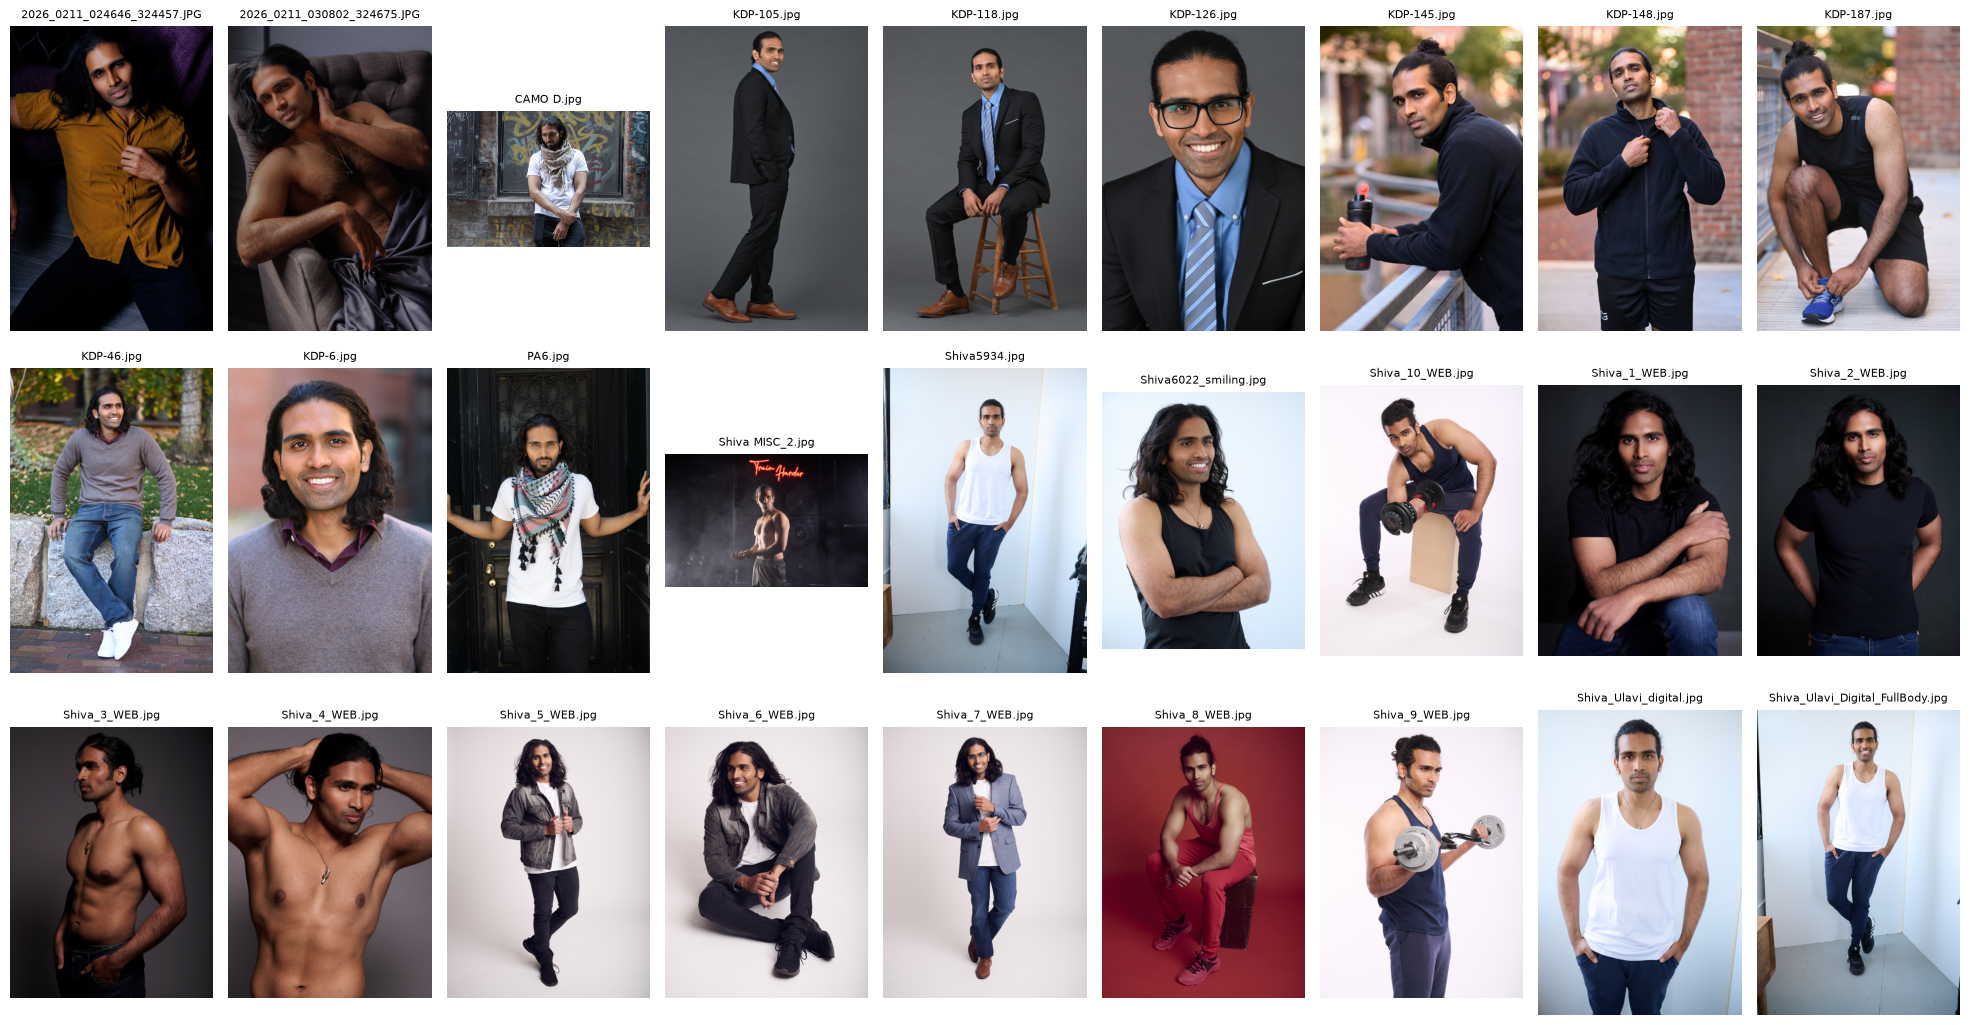

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import math

# Define layout dimensions
rows = 3
total_images = len(image_paths)
cols = math.ceil(total_images / rows)  # This will automatically calculate 9 columns for 27 images

# Set up the subplot grid (3 rows, 9 columns)
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 3.5))

# Flatten the 2D axes array into a 1D list so we can loop through them linearly
axes_flat = axes.flatten()

# Loop through each image path and display it on its corresponding grid cell
for ax, path in zip(axes_flat, image_paths):
    img = Image.open(path)
    ax.imshow(img)
    ax.axis('off')  # Hide axis borders/ticks
    ax.set_title(path.name, fontsize=8)  # Compact font size for captions

# Hide any empty subplot boxes if the total image count isn't an exact multiple
for ax in axes_flat[total_images:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

```markdown
## 6. Asynchronous Batch Evaluation Setup
To avoid hitting rate limits while maintaining fast execution, we use `asyncio.Semaphore` with a concurrency limit of 3 (`SEMAPHORE_LIMIT = 3`). This allows us to process 3 image analysis tasks concurrently.
```

In [ ]:
from langchain_core.messages import HumanMessage
import asyncio
from pathlib import Path

SEMAPHORE_LIMIT = 3

async def process_image_async(image_path: Path, index: int, semaphore: asyncio.Semaphore, structured_llm):
    async with semaphore:
        try:
            encoded_string, mime_type = encode_and_resize_image(image_path)

            messages = [HumanMessage(
                content=[
                    {"type": "text", "text": f"Evaluate this look for look number {index+1} from a modeling portfolio."},
                    {"type": "image_url",  "image_url": {"url": f"data:{mime_type};base64,{encoded_string}"}}
                ]
            )]

            response = await structured_llm.ainvoke(messages)
            return index, response, None

        except Exception as e:
            return index, None, str(e)

async def run_batch_evaluation(image_paths, structured_llm):
    semaphore = asyncio.Semaphore(SEMAPHORE_LIMIT)
    print(f"Starting asynchronous batch processing for {len(image_paths)} images (Concurrency limit: {SEMAPHORE_LIMIT})...")
    tasks = [
        process_image_async(path, idx, semaphore, structured_llm) for idx,path in enumerate(image_paths)
    ]
    results = await asyncio.gather(*tasks)
    return results


```markdown
## 7. Running the Batch Job
We invoke the asynchronous batch process over all 27 images and sort the incoming structured responses by their original indices.
```

In [ ]:
image_results = await run_batch_evaluation(image_paths, structured_portfolio_llm)

# Process and sort results by original index
sorted_results = sorted(image_results, key=lambda x: x[0])
for idx, response, error in sorted_results:
    if error:
        print(f"Image {idx+1}: Error - {error}")
    else:
        print(f"Image {idx+1}: Success -> Score / Genre: {response.primary_mood_or_genre if hasattr(response, 'primary_mood_or_genre') else 'Evaluated'}")

Starting asynchronous batch processing for 27 images (Concurrency limit: 3)...
Image 1: Success -> Score / Genre: Evaluated
Image 2: Success -> Score / Genre: Evaluated
Image 3: Success -> Score / Genre: Evaluated
Image 4: Success -> Score / Genre: Evaluated
Image 5: Success -> Score / Genre: Evaluated
Image 6: Success -> Score / Genre: Evaluated
Image 7: Success -> Score / Genre: Evaluated
Image 8: Success -> Score / Genre: Evaluated
Image 9: Success -> Score / Genre: Evaluated
Image 10: Success -> Score / Genre: Evaluated
Image 11: Success -> Score / Genre: Evaluated
Image 12: Success -> Score / Genre: Evaluated
Image 13: Success -> Score / Genre: Evaluated
Image 14: Success -> Score / Genre: Evaluated
Image 15: Success -> Score / Genre: Evaluated
Image 16: Success -> Score / Genre: Evaluated
Image 17: Success -> Score / Genre: Evaluated
Image 18: Success -> Score / Genre: Evaluated
Image 19: Success -> Score / Genre: Evaluated
Image 20: Success -> Score / Genre: Evaluated
Image 21: 

```markdown
## 8. Inspecting Individual Evaluation Artifacts
Let's verify the structured metadata returned by the vision LLM for a subset of our portfolio looks to confirm everything parsed correctly.
```

In [ ]:
sorted_results[1:5]

[(1,
  PortfolioEvaluation(overall_versatility_score=8, looks=[LookBreakdown(look_number=2, primary_mood_or_genre='Moody Editorial / Sensual Boudoir', wardrobe_and_styling='Shirtless with draped fabric; silver chain necklace; natural body hair', ideal_campaign_fit='Fragrance, luxury underwear, high-end jewelry, or avant-garde fashion campaigns')], cohesion_and_critique="This is a very strong, high-impact editorial look. It successfully showcases the model's raw physicality and comfort with sensual, moody styling. As Look #2, it provides excellent contrast to a standard, clean commercial headshot or a tailored suit look, proving his range and versatility."),
  None),
 (2,
  PortfolioEvaluation(overall_versatility_score=8, looks=[LookBreakdown(look_number=3, primary_mood_or_genre='Urban Street / Gritty Editorial / Indie', wardrobe_and_styling="The styling is excellent for this specific vibe. The crisp white tee acts as a blank canvas, allowing the textures around him to do the heavy lift

```markdown
## 9. Creating the Creative Director LCEL Chain
Now, we feed the structured feedback for all 27 looks into a master creative director prompt. We use a high-reasoning model (`gpt-4o`) via LangChain Expression Language (LCEL) to synthesize the individual results into an authoritative creative strategy document.
```

In [ ]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate

# 1. Defining the prompt template updated for Commercial & Print modeling
creative_critique_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        (
            "You are an expert Commercial and Print Modeling Agent and Creative Director. "
            "Your task is to write a comprehensive, professional portfolio assessment and creative critique for a commercial and print model "
            "seeking profile growth, advertising campaigns, e-commerce placement, and agency representation.\n\n"
            "Guidelines:\n"
            "1. Analyze the structured evaluation data provided for each look in sequence.\n"
            "2. Highlight commercial appeal, marketability, approachable confidence, eye contact, and posing versatility across lifestyle, corporate, and advertising sectors.\n"
            "3. Provide constructive feedback on styling, grooming, wardrobe, and expression tailored to commercial print standards to elevate overall portfolio cohesion and market readiness."
        ),
    ),
    (
        "user",
        (
            "Here is the structured evaluation data extracted from our "
            "portfolio session:\n\n{portfolio_metadata_list}"
        ),
    ),
])

```markdown
## 10. Generating the Final Executive Report
Run the model-independent critique synthesis chain to print the finalized portfolio assessment.
```

In [ ]:
critique_llm = ChatOpenAI(model="gpt-4o")
# 2. Build the LCEL chain using the Lambda dictionary mapping pattern
chain = (
    {
        "portfolio_metadata_list": lambda inputs: "\n\n".join([
            f"Look {i+1} Details:\n{response.model_dump_json(indent=2)}"
            for i, (idx, response, error) in enumerate(inputs)
            if response is not None  # Filters out any failed images gracefully
        ])
    }
    | creative_critique_prompt
    | critique_llm
    | StrOutputParser()
)
# 3. Invoke the chain with your list of structured look evaluations
final_critique = chain.invoke(sorted_results)

print("--- Professional Portfolio Executive Critique ---")
print(final_critique)

--- Professional Portfolio Executive Critique ---
**Comprehensive Portfolio Assessment and Creative Critique**

**General Overview**

The model showcases a solid range of styles and moods across multiple looks, highlighting commercial appeal, versatility, and marketability. The portfolio effectively balances lifestyle, corporate, and advertising-specific imagery, showcasing an approachable yet confident demeanor that is attractive to a range of clients and casting directors.

---

**Look 1 to Look 10: Establishing Versatility**

- **Look 1 and 2**: These initial looks open strong with a marketable and impactful vibe. They showcase raw physicality with a high editorial value. The challenge is to avoid niche pigeonholing by complementing them with more versatile, relatable looks in the portfolio.
  
- **Look 3**: Embraces an urban, gritty style, fitting well within indie lifestyle and streetwear brands. It's a solid editorial moment that can capture attention in creatives focused on musi